# Stage 2: Text Recognition on the Cleaned Image (OCR vs HTR)

This notebook continues `preprocessing.ipynb`. It reads the images you saved in Stage 1 and compares two ways of turning them into text:

| | **OCR** (this notebook: Tesseract) | **HTR** (this notebook: TrOCR) |
|---|---|---|
| Meant for | printed text | handwritten text |
| How it works | classic engine with a neural line recognizer, trained mostly on printed fonts | Vision Transformer encoder + text Transformer decoder, trained on handwriting |
| Input | a page or a text line | one **text line** at a time |

**Pipeline of this notebook:** load cleaned images → segment into text lines → OCR each → HTR each → score both against your transcription (CER, WER) → save tables and figures for the paper.

**You need before running:**
1. The Stage 1 outputs in `outputs/processed_images/` (`07_final.png` and `05_deskewed.png`).
2. A ground-truth transcription of the page in `data/ground_truth/sample.txt`, **one manuscript line per text line**, in reading order, with accents. Without it the notebook still produces text, but it cannot compute accuracy.

## Step 0. Install the libraries

| Library | Purpose |
|---|---|
| `opencv-python`, `numpy`, `pillow` | image handling and line cropping |
| `pytesseract` | Python wrapper for the Tesseract OCR engine |
| `torch`, `transformers` | run the TrOCR handwriting model |
| `jiwer` | CER and WER metrics |
| `pandas`, `matplotlib` | result tables and figures |

**Tesseract itself is a separate program** and must be installed on your computer, with the **Spanish** language data (`spa`):
- **Windows:** install from the UB Mannheim build and tick *Spanish* under additional language data. If Python cannot find it, uncomment the `tesseract_cmd` line in Step 1.
- **macOS:** `brew install tesseract tesseract-lang`
- **Ubuntu/Debian:** `sudo apt install tesseract-ocr tesseract-ocr-spa`

The first run of TrOCR downloads the model (about 1.3 GB for the base model), so you need an internet connection once.

In [ ]:
%pip install -q opencv-python numpy pillow pandas matplotlib pytesseract jiwer
%pip install -q torch transformers

## Step 1. Settings
All the things you may want to change are in this one cell.

In [11]:
import os, re, time, unicodedata
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Works whether Jupyter was started in the project folder or inside notebooks/
ROOT = "." if os.path.isdir("data") else ".."

# --- Inputs (outputs of Stage 1) ---
PROC_DIR = os.path.join(ROOT, "outputs", "processed_images")
IMAGE_VARIANTS = {
    "binarized": os.path.join(PROC_DIR, "07_final.png"),      # black text on white
    "grayscale": os.path.join(PROC_DIR, "05_deskewed.png"),   # CLAHE + deskewed, not thresholded
}
GROUND_TRUTH_PATH = os.path.join(ROOT, "data", "ground_truth", "sample.txt")

# --- Engines ---
OCR_LANG = "spa"                                   # Tesseract language data
HTR_MODEL = "microsoft/trocr-base-handwritten"     # or "microsoft/trocr-small-handwritten" (lighter),
                                                   # or the folder of your own fine-tuned model
NUM_BEAMS = 4                                      # beam search width for TrOCR (1 = fastest)
BATCH_SIZE = 8

# --- Line segmentation (tune on your own scans; Step 3 explains each setting) ---
SEGMENT_ON = "binarized"       # image used to find the lines: "binarized" or "grayscale"
MIN_COMPONENT_AREA = 20        # ignore specks smaller than this many pixels
SMEAR_WIDTH_FACTOR = 3.0       # sideways smear, in letter heights: raise it if one line is cut into pieces
SMEAR_HEIGHT_FACTOR = 0.3      # vertical smear, in letter heights: lower it if two lines are merged
SPLIT_TALL_LINES = True        # cut blobs that are about two lines tall (lines that touch)
MIN_LINE_HEIGHT = 15           # pixels
MIN_INK_RATIO = 0.1            # drop 'lines' with less than this fraction of a typical line's ink (stray marks)
PAD_X, PAD_Y = 12, 8
MANUAL_BOXES = None            # or a list of (x0, y0, x1, y1) if automatic segmentation fails

OUT_DIR = os.path.join(ROOT, "outputs", "recognition")
os.makedirs(OUT_DIR, exist_ok=True)

# import pytesseract
# pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"   # Windows, if needed

## Step 2. Load the cleaned images and the ground truth
**Ground truth:** to measure accuracy you need a human transcription of the page: a text file with **one line per manuscript line**, in reading order, with accents, saved at `GROUND_TRUTH_PATH`. If you do not have one yet, run on: Step 5b writes a template you only have to correct.

We load every available variant. Comparing the **binarized** image with the **grayscale** one is useful: Tesseract usually does its own thresholding, and TrOCR was trained on grayscale-looking handwriting, so a hard black-and-white image does not always help each engine equally.

In [22]:
variants = {}
for name, path in IMAGE_VARIANTS.items():
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None:
        print(f"[skip] {name}: could not read {path}")
    else:
        variants[name] = im
        print(f"[ok]   {name}: {im.shape}")
assert variants, "No input images found. Run preprocessing.ipynb first."
assert len({im.shape for im in variants.values()}) == 1, "All variants must have the same size."

truth_lines = None
gt_abs = os.path.abspath(GROUND_TRUTH_PATH)
if os.path.exists(GROUND_TRUTH_PATH):
    with open(GROUND_TRUTH_PATH, encoding="utf-8") as f:
        truth_lines = [ln.strip() for ln in f.read().splitlines() if ln.strip()]
if truth_lines:
    print(f"Ground truth: {len(truth_lines)} lines, read from {gt_abs}")
else:
    gt_dir = os.path.dirname(gt_abs)
    print("=" * 70)
    print("NO GROUND TRUTH LOADED. Steps 6 to 9 cannot score accuracy without it.")
    print("Looked for:", gt_abs, "(file is empty)" if os.path.exists(GROUND_TRUTH_PATH) else "(file not found)")
    print("Files in that folder:", sorted(os.listdir(gt_dir)) if os.path.isdir(gt_dir) else "(the folder does not exist)")
    print("Easiest fix: run on, and Step 5b will write a transcription template for you to correct.")
    print("Or point GROUND_TRUTH_PATH in Step 1 at your own file.")
    print("=" * 70)

[ok]   binarized: (1168, 848)
[ok]   grayscale: (1168, 848)
Ground truth: 22 lines, read from /home/domo/Documents/Project Midterms/data/ground_truth/sample.txt


## Step 3. Segment the page into text lines
HTR models such as TrOCR read **one line at a time**, so we first cut the page into lines. Real manuscripts have tilted, wavy and touching lines, so a simple row-by-row ink count is not enough. This step works in five moves:

1. **Find the ink** (Otsu threshold, with an automatic check that the text is the minority colour).
2. **Clean it:** remove specks, ruled lines, margin lines and scan borders (long, very thin shapes, even when slightly slanted).
3. **Smear the ink sideways** so the letters and words of one line fuse into a single blob. This works even when the line is tilted or curved.
4. **Join and split blobs:** blobs side by side on the same line are joined; a blob about two lines tall (lines that touch) is cut at its emptiest row.
5. **Mask each line:** ink that belongs to a neighbouring line is erased from the crop.

We segment once and crop the **same boxes** from every variant, so all comparisons use identical lines. The three panels below show what the algorithm saw, so you can tell *why* a line was missed.

| Problem you see | What to change in Step 1 |
|---|---|
| Two lines in one box | lower `SMEAR_HEIGHT_FACTOR` (try 0.1) |
| One line cut into several boxes | raise `SMEAR_WIDTH_FACTOR` (try 5) |
| A faint line is missing | look at the middle panel; if its ink is missing, set `SEGMENT_ON = "grayscale"` or lower `MIN_COMPONENT_AREA` |
| Extra boxes on stamps, margins or stains | raise `MIN_INK_RATIO` (try 0.25) |
| Nothing works | give the boxes yourself in `MANUAL_BOXES` |

Detected 28 text lines (segmented on the 'binarized' image)


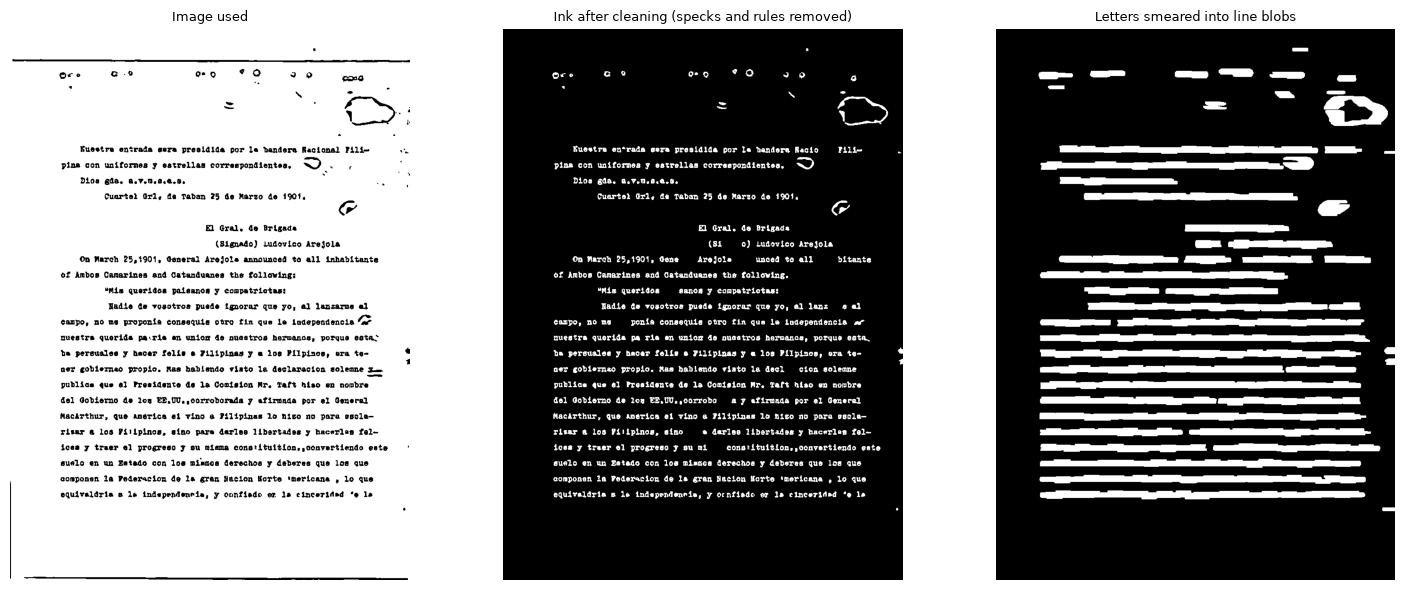

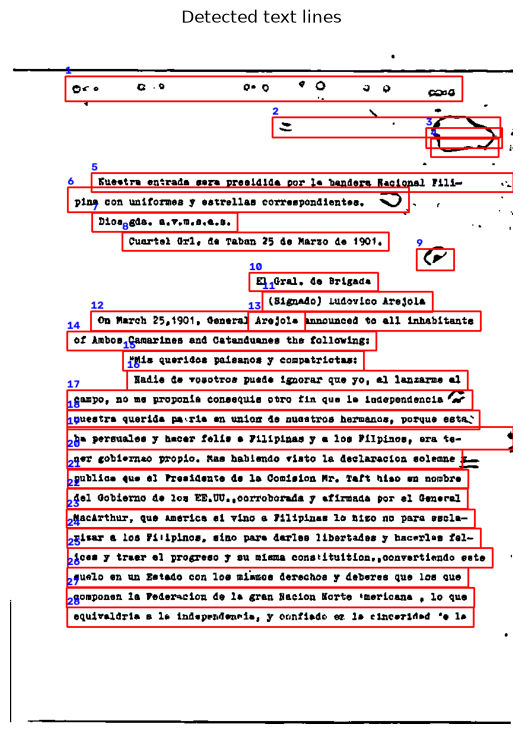

In [23]:
def ink_mask(gray):
    # Dark ink on light paper -> white ink on black. If the 'ink' covers more than half
    # the page the polarity is wrong, so flip it.
    _, ink = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    if ink.mean() > 127:
        ink = cv2.bitwise_not(ink)
    return ink

def remove_rules_and_specks(ink):
    H, W = ink.shape
    # 1) Ruled lines, margin lines and scan borders: very long, thin runs of ink
    hk = cv2.getStructuringElement(cv2.MORPH_RECT, (max(W // 4, 25), 1))
    vk = cv2.getStructuringElement(cv2.MORPH_RECT, (1, max(H // 4, 25)))
    rules = cv2.bitwise_or(cv2.morphologyEx(ink, cv2.MORPH_OPEN, hk),
                           cv2.morphologyEx(ink, cv2.MORPH_OPEN, vk))
    ink = cv2.bitwise_and(ink, cv2.bitwise_not(cv2.dilate(rules, np.ones((3, 3), np.uint8))))
    # 2) Specks (too small) and stains or borders (too tall)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(ink, connectivity=8)
    keep = (stats[:, cv2.CC_STAT_AREA] >= MIN_COMPONENT_AREA) & (stats[:, cv2.CC_STAT_HEIGHT] < 0.25 * H)
    keep[0] = False                                   # label 0 is the background
    # 3) Slightly slanted rules, margin lines and border strips survive step 1 (often in pieces).
    #    They are long but very thin whatever their tilt, so measure the thickness of the
    #    rotated bounding rectangle of every component that is long compared with a letter.
    ch0 = float(np.median(stats[keep, cv2.CC_STAT_HEIGHT])) if keep.any() else 0.0
    longer = np.maximum(stats[:, cv2.CC_STAT_WIDTH], stats[:, cv2.CC_STAT_HEIGHT]) > 2.5 * ch0
    for i in np.nonzero(keep & longer)[0]:
        x, y, w, h = [int(v) for v in stats[i, :4]]
        pts = np.column_stack(np.nonzero(labels[y:y + h, x:x + w] == i))[:, ::-1].astype(np.float32)
        (_, (rw, rh), _) = cv2.minAreaRect(pts)
        if min(rw, rh) < 0.012 * H:
            keep[i] = False
    return (keep[labels] * 255).astype(np.uint8), stats[keep, cv2.CC_STAT_HEIGHT]

def segment_lines(gray):
    H, W = gray.shape
    clean, heights = remove_rules_and_specks(ink_mask(gray))
    if len(heights) == 0:
        return [], [], {"clean": clean, "smear": clean}
    ch = float(np.median(heights))                    # typical letter/word height in pixels

    # Smear the ink sideways so the letters and words of one line fuse into one blob.
    # Unlike a row-by-row ink count, this still works when lines are tilted or wavy.
    kw = max(int(SMEAR_WIDTH_FACTOR * ch), 15)
    kh = max(int(SMEAR_HEIGHT_FACTOR * ch), 3)
    smear = cv2.dilate(clean, cv2.getStructuringElement(cv2.MORPH_RECT, (kw, kh)))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(smear, connectivity=8)

    # One candidate per blob, measured on the real ink (not on the smeared blob)
    cands = []
    for i in range(1, n):
        x, y, w, h, _ = stats[i]
        sub = (labels[y:y + h, x:x + w] == i) & (clean[y:y + h, x:x + w] > 0)
        ys, xs = np.nonzero(sub)
        if len(ys) == 0:
            continue
        cands.append({"x0": x + xs.min(), "x1": x + xs.max() + 1,
                      "y0": y + ys.min(), "y1": y + ys.max() + 1,
                      "ink": len(ys), "ids": {i}})

    # Join blobs that sit side by side on the same line (big word gaps, indents, signatures)
    cands.sort(key=lambda c: (c["y0"] + c["y1"]) / 2)
    lines = []
    for c in cands:
        for L in lines:
            small_h = min(c["y1"] - c["y0"], L["y1"] - L["y0"])
            small_w = min(c["x1"] - c["x0"], L["x1"] - L["x0"])
            v_over = min(c["y1"], L["y1"]) - max(c["y0"], L["y0"])
            h_over = min(c["x1"], L["x1"]) - max(c["x0"], L["x0"])
            if v_over > 0.5 * small_h and h_over < 0.2 * small_w:
                L["x0"], L["x1"] = min(L["x0"], c["x0"]), max(L["x1"], c["x1"])
                L["y0"], L["y1"] = min(L["y0"], c["y0"]), max(L["y1"], c["y1"])
                L["ink"] += c["ink"]
                L["ids"] = L["ids"] | c["ids"]
                break
        else:
            lines.append(dict(c))

    # Lines that touch (descenders meeting the next line's ascenders) end up as one tall blob.
    # Cut such blobs at the emptiest rows, where one line ends and the next begins.
    if SPLIT_TALL_LINES and len(lines) >= 2:
        pitch = float(np.median([L["y1"] - L["y0"] for L in lines]))
        out = []
        for L in lines:
            h = L["y1"] - L["y0"]
            parts = int(round(h / pitch))
            if h > 1.6 * pitch and parts >= 2:
                prof = (clean[L["y0"]:L["y1"], L["x0"]:L["x1"]] > 0).sum(axis=1).astype(float)
                prof = np.convolve(prof, np.ones(5) / 5, mode="same")
                cuts = [0]
                for k in range(1, parts):
                    mid = int(k * h / parts)
                    lo = max(mid - int(0.25 * pitch), cuts[-1] + 1)
                    hi = min(mid + int(0.25 * pitch), h - 1)
                    cuts.append(lo + int(np.argmin(prof[lo:hi])) if hi > lo else mid)
                cuts.append(h)
                for a, b in zip(cuts[:-1], cuts[1:]):
                    ys, xs = np.nonzero(clean[L["y0"] + a:L["y0"] + b, L["x0"]:L["x1"]])
                    if len(ys):
                        out.append({"x0": L["x0"] + xs.min(), "x1": L["x0"] + xs.max() + 1,
                                    "y0": L["y0"] + a + ys.min(), "y1": L["y0"] + a + ys.max() + 1,
                                    "ink": len(ys), "ids": L["ids"]})
            else:
                out.append(L)
        lines = out

    # Drop stray marks: too short, too narrow, or hardly any ink compared with a typical line
    if not lines:
        return [], [], {"clean": clean, "smear": smear}
    ink_med = float(np.median([L["ink"] for L in lines]))
    lines = [L for L in lines
             if (L["y1"] - L["y0"]) >= MIN_LINE_HEIGHT
             and (L["x1"] - L["x0"]) >= 2 * ch
             and L["ink"] >= MIN_INK_RATIO * ink_med]

    # Reading order, padded boxes, and a mask per line that hides ink of neighbouring lines
    grow = int(0.4 * ch) // 2 * 2 + 1
    boxes, masks = [], []
    for L in sorted(lines, key=lambda L: (L["y0"] + L["y1"]) / 2):
        x0, y0 = max(int(L["x0"]) - PAD_X, 0), max(int(L["y0"]) - PAD_Y, 0)
        x1, y1 = min(int(L["x1"]) + PAD_X, W), min(int(L["y1"]) + PAD_Y, H)
        m = np.isin(labels[y0:y1, x0:x1], list(L["ids"])).astype(np.uint8)
        m = cv2.dilate(m, np.ones((grow, grow), np.uint8)) > 0
        boxes.append((x0, y0, x1, y1))
        masks.append(m)
    return boxes, masks, {"clean": clean, "smear": smear}

def crop_lines(gray, boxes, masks=None, border=6):
    crops = []
    for i, (x0, y0, x1, y1) in enumerate(boxes):
        c = gray[y0:y1, x0:x1].copy()
        if masks is not None:
            c[~masks[i]] = 255                        # erase ink that belongs to neighbouring lines
        crops.append(cv2.copyMakeBorder(c, border, border, border, border,
                                        cv2.BORDER_CONSTANT, value=255))
    return crops

SEGMENT_ON = SEGMENT_ON if SEGMENT_ON in variants else next(iter(variants))
seg_image = variants[SEGMENT_ON]

if MANUAL_BOXES:
    boxes, masks, debug = MANUAL_BOXES, None, None
else:
    boxes, masks, debug = segment_lines(seg_image)
print(f"Detected {len(boxes)} text lines (segmented on the '{SEGMENT_ON}' image)")
if truth_lines and len(boxes) != len(truth_lines):
    print(f"WARNING: ground truth has {len(truth_lines)} lines but {len(boxes)} were detected. "
          "Page-level scores still work; per-line comparison will be skipped. "
          "Check the panels below, then see the table above and Step 1, or set MANUAL_BOXES.")

# What did the algorithm see?
if debug is not None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))
    for ax, im, title in zip(axes, [seg_image, debug["clean"], debug["smear"]],
                             ["Image used", "Ink after cleaning (specks and rules removed)", "Letters smeared into line blobs"]):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(title, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

vis = cv2.cvtColor(seg_image, cv2.COLOR_GRAY2BGR)
for i, (x0, y0, x1, y1) in enumerate(boxes, 1):
    cv2.rectangle(vis, (x0, y0), (x1, y1), (0, 0, 255), 2)
    cv2.putText(vis, str(i), (x0, max(y0 - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
plt.figure(figsize=(7, 9)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("Detected text lines"); plt.show()
cv2.imwrite(os.path.join(OUT_DIR, "line_segmentation.png"), vis)

# Crop the same boxes from every variant (neighbouring lines' ink erased, white border added)
crops = {name: crop_lines(im, boxes, masks) for name, im in variants.items()}

## Step 4. OCR with Tesseract
We run Tesseract in two ways:
- **Full page** (`--psm 6`, one uniform block of text): how OCR is normally used, with Tesseract doing its own layout analysis.
- **Per line** (`--psm 7`, a single text line): the fair comparison with HTR, since both engines then see exactly the same line images.

If the Spanish data is missing, the notebook falls back to English and **warns you**. Do not report those numbers in the paper.

In [24]:
import pytesseract

available = pytesseract.get_languages(config="")
ocr_lang = OCR_LANG
if OCR_LANG not in available:
    ocr_lang = "eng"
    print("=" * 70)
    print(f"WARNING: Tesseract language '{OCR_LANG}' is not installed (found: {available}).")
    print("Falling back to 'eng'. Install the Spanish data before reporting results.")
    print("=" * 70)
print("Tesseract:", pytesseract.get_tesseract_version(), "| language used:", ocr_lang)

predictions = {}   # (engine_mode, variant) -> list of text lines
timings = {}

for name, im in variants.items():
    t0 = time.perf_counter()
    text = pytesseract.image_to_string(im, lang=ocr_lang, config="--psm 6")
    timings[("Tesseract full page", name)] = time.perf_counter() - t0
    predictions[("Tesseract full page", name)] = [ln.strip() for ln in text.splitlines() if ln.strip()]

    t0 = time.perf_counter()
    lines = [pytesseract.image_to_string(c, lang=ocr_lang, config="--psm 7").strip() for c in crops[name]]
    timings[("Tesseract per line", name)] = time.perf_counter() - t0
    predictions[("Tesseract per line", name)] = lines

for key in predictions:
    if key[0].startswith("Tesseract"):
        print(f"\n--- {key[0]} | {key[1]} ({timings[key]:.2f}s) ---")
        print("\n".join(predictions[key]))

Tesseract: 5.3.4 | language used: spa

--- Tesseract full page | binarized (1.02s) ---
(€ ---A-—— o
oro o. O] co 22 coa
< Ñ - .
Y e
Fuestra entrada sera presidida por la handora Racional Fili- ve
pina con uniformes y estrellas correspondientes, O oe ?
Dios gde. 8.7.M.8.8.5. z o. :
Cuartel 011, de Taban 25 de Marzo de 1901,
(6
El Gral, de Brigada
(signado) Ludovico Arejola
On March 25,1901, Oeneral Árejole announced to ell inhabítante
0f Ambos Camarines and Catanduanes the following;
*mMás queridos palsanos y compatrictas:
Nadia €s vosotros puede Ignorar que yo, el lanzarme al
carpo, no ma proponía consequís otro tin que le independencia LAS
vuestra querida pa:rie en uniox 4s nuestros hermanos, porque estas
ha persuales y hacer felís e Filípinas y e los Pílpinos, ora te- 4
ner goblernao propio. Mas hablendo viato la declaracion solemne La 1
publicas que el Presidents de la Comision Mr, Taft hiso en nombre
del Gobierno de loz EE.UU, corroborada y «firmada por el Cenerel
Macárthur, qué am

## Step 5. HTR with TrOCR
TrOCR resizes every input to a 384 x 384 square, so very long lines are squeezed and lose detail. If your lines are long, split them into two halves before recognition.

**Important for your paper:** `microsoft/trocr-base-handwritten` was trained on **English** handwriting (IAM dataset). It has never been trained on Spanish accents (á, é, í, ó, ú, ñ) or on period handwriting, so expect errors on those. That is a finding worth reporting, and it motivates fine-tuning on your own transcribed lines. To test a fine-tuned model later, set `HTR_MODEL` to its folder.

In [25]:
HTR_READY = False
try:
    import torch
    from transformers import TrOCRProcessor, VisionEncoderDecoderModel

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Loading", HTR_MODEL, "on", device, "(first run downloads the model)...")
    processor = TrOCRProcessor.from_pretrained(HTR_MODEL)
    htr_model = VisionEncoderDecoderModel.from_pretrained(HTR_MODEL).to(device).eval()
    HTR_READY = True
except Exception as e:
    print("=" * 70)
    print("HTR step skipped, the model could not be loaded:")
    print(repr(e)[:400])
    print("Check your internet connection and that torch/transformers are installed.")
    print("=" * 70)

def htr_recognize(line_crops):
    texts = []
    for i in range(0, len(line_crops), BATCH_SIZE):
        batch = [Image.fromarray(c).convert("RGB") for c in line_crops[i:i + BATCH_SIZE]]
        pixel_values = processor(images=batch, return_tensors="pt").pixel_values.to(device)
        with torch.no_grad():
            ids = htr_model.generate(pixel_values, num_beams=NUM_BEAMS, max_new_tokens=64)
        texts += processor.batch_decode(ids, skip_special_tokens=True)
    return [t.strip() for t in texts]

if HTR_READY:
    htr_recognize(crops[next(iter(crops))][:1])      # warm-up run so timings are fair
    for name in variants:
        t0 = time.perf_counter()
        predictions[("TrOCR per line", name)] = htr_recognize(crops[name])
        timings[("TrOCR per line", name)] = time.perf_counter() - t0
        print(f"\n--- TrOCR per line | {name} ({timings[('TrOCR per line', name)]:.2f}s) ---")
        print("\n".join(predictions[("TrOCR per line", name)]))

Loading microsoft/trocr-base-handwritten on cuda (first run downloads the model)...


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



--- TrOCR per line | binarized (25.93s) ---
000 0.0.000
" 2 )
I 9 .
2nd
Kuestra entrada para presidida por la handora Racione : PILL-
pins con uniformes y estrellas correspondientes . "
DLOS EAS. B.F.M.S.B.S.
Quartet Orl. de Raben 25 de Marzo de 1901 .
er
El Gral . do Brigade
(81endol Ludovico Angola
On March 25 1901 , Oeners , was loaned to all : abitants .
" Aregois .
of Arbor Canarines and Catanduanes the following :
while queridos ; cleanos y compatriotas :
Nadie de vosotros puede ignorar que yo , el lansarre el
cargo , no me , reports consquite zero tin que la independenta "
nuestra querida patria en unior de nuestros hermanos , porque esta ;
be persuades y hacer tells a Filipinas y a los Pilpino , era to- It
nor goblormas propio . has hadlendo vlato la declasacion solenne :
publics que el Presidento de la Comision Mr. Taft also en nombre
del Gobierno de los EB.00,corroborada y atimosa por el General
Mackrthur , que america et vino a Filipinas is nico no para seda-
risar a los Fi

## Step 5b. Make your ground truth (about two minutes)
Accuracy scores need a human transcription of the page. This step makes that quick:

1. It saves every detected line as a numbered image in `outputs/recognition/lines/`.
2. It writes `ground_truth_TEMPLATE.txt` with **one row per detected line**, pre-filled with Tesseract's reading. Open the line images, **correct each row** so it says what the manuscript really says (keep the same order and the same number of rows; do not delete or merge rows), and save it as your ground-truth file. A row marked `[?]` means the engine read nothing for that line.
3. Re-run from Step 2. Steps 6 to 9 will then score both engines.

Because the template has exactly one row per detected line, the line-by-line table in Step 8 lines up automatically. If a line is wrongly cut or merged, fix the segmentation in Step 3 first, so that rows and lines agree.

In [26]:
LINES_DIR = os.path.join(OUT_DIR, "lines")
os.makedirs(LINES_DIR, exist_ok=True)
ref_variant = next(iter(crops))
for i, c in enumerate(crops[ref_variant], 1):
    cv2.imwrite(os.path.join(LINES_DIR, f"line_{i:02d}.png"), c)
print(f"Saved {len(boxes)} line images to {os.path.abspath(LINES_DIR)}")

if truth_lines:
    print("Ground truth already loaded, so no template was written.")
else:
    per_line_keys = [k for k in predictions if k[0].endswith("per line") and k[1] == ref_variant]
    if per_line_keys:
        guess = predictions[per_line_keys[0]]
        template_path = os.path.join(OUT_DIR, "ground_truth_TEMPLATE.txt")
        with open(template_path, "w", encoding="utf-8") as f:
            f.write("\n".join(g if g.strip() else "[?]" for g in guess))
        print(f"Wrote a starting transcription ({len(guess)} rows) to {os.path.abspath(template_path)}")
        print("Correct it against the line images, save it as", os.path.abspath(GROUND_TRUTH_PATH), "and re-run from Step 2.")
    else:
        print("No per-line reading available to build a template from.")

Saved 28 line images to /home/domo/Documents/Project Midterms/outputs/recognition/lines
Ground truth already loaded, so no template was written.


## Step 6. Score against the ground truth
- **CER** (character error rate) = (substitutions + insertions + deletions) / characters in the truth. Lower is better.
- **WER** (word error rate) is the same at word level.
- **Strict** scores compare exactly (case, accents, punctuation). **Relaxed** scores ignore case, accents and punctuation. The gap between the two shows how much of the error is only accents and capitals, which matters for Spanish.

Scores are computed on the whole page (lines joined with spaces), so they work even if the line counts differ. They can exceed 100% when the engine inserts a lot of extra text.

In [27]:
import jiwer

def normalize(text, relaxed=False):
    text = unicodedata.normalize("NFC", text)
    if relaxed:
        text = text.lower()
        text = "".join(c for c in unicodedata.normalize("NFD", text) if unicodedata.category(c) != "Mn")
        text = re.sub(r"[^\w\s]", "", text)
    return re.sub(r"\s+", " ", text).strip()

def score(pred_lines, truth, relaxed):
    ref = normalize(" ".join(truth), relaxed)
    hyp = normalize(" ".join(pred_lines), relaxed)
    return jiwer.cer(ref, hyp) * 100, jiwer.wer(ref, hyp) * 100

rows = []
for (mode, variant), pred in predictions.items():
    row = {
        "Engine": mode,
        "Type": "HTR" if mode.startswith("TrOCR") else "OCR",
        "Input image": variant,
        "Lines read": len(pred),
        "Time (s)": round(timings[(mode, variant)], 2),
    }
    if truth_lines:
        cer, wer = score(pred, truth_lines, relaxed=False)
        cer_r, wer_r = score(pred, truth_lines, relaxed=True)
        row.update({"CER %": round(cer, 1), "WER %": round(wer, 1),
                    "CER % (relaxed)": round(cer_r, 1), "WER % (relaxed)": round(wer_r, 1)})
    rows.append(row)

results = pd.DataFrame(rows)
results["Language / model"] = np.where(results["Type"] == "OCR", f"Tesseract '{ocr_lang}'", HTR_MODEL)
results.to_csv(os.path.join(OUT_DIR, "results.csv"), index=False)
if not truth_lines:
    print("No ground truth loaded: only lines read and time can be shown. See Step 5b to make one.")
results

,Engine,Type,Input image,Lines read,Time (s),CER %,WER %,CER % (relaxed),WER % (relaxed),Language / model
0,Tesseract full page,OCR,binarized,28,1.02,15.3,54.7,11.1,41.8,Tesseract 'spa'
1,Tesseract per line,OCR,binarized,28,2.69,16.0,53.7,12.9,43.8,Tesseract 'spa'
2,Tesseract full page,OCR,grayscale,28,0.89,9.4,32.8,6.8,24.9,Tesseract 'spa'
3,Tesseract per line,OCR,grayscale,28,2.68,12.9,37.8,10.4,31.3,Tesseract 'spa'
4,TrOCR per line,HTR,binarized,28,25.93,22.6,70.1,19.1,47.3,microsoft/trocr-base-handwritten
5,TrOCR per line,HTR,grayscale,28,27.06,28.9,82.1,24.1,60.2,microsoft/trocr-base-handwritten


## Step 7. Comparison figure

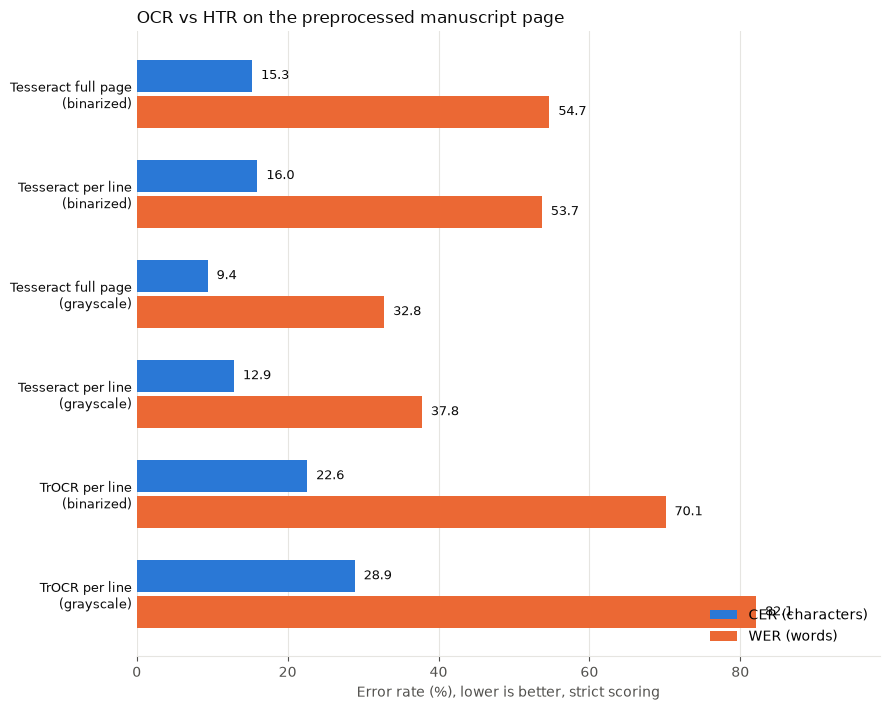

In [28]:
if truth_lines:
    BLUE, ORANGE = "#2a78d6", "#eb6834"          # validated categorical pair from the dataviz palette
    INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

    labels = [f"{r['Engine']}\n({r['Input image']})" for _, r in results.iterrows()]
    y = np.arange(len(results))
    h = 0.36

    fig, ax = plt.subplots(figsize=(9, 0.9 * len(results) + 1.8))
    b1 = ax.barh(y - h / 2, results["CER %"], h - 0.04, color=BLUE, label="CER (characters)")
    b2 = ax.barh(y + h / 2, results["WER %"], h - 0.04, color=ORANGE, label="WER (words)")
    xmax = max(results[["CER %", "WER %"]].max().max(), 1) * 1.2
    for bars in (b1, b2):
        for bar in bars:
            ax.text(bar.get_width() + xmax * 0.012, bar.get_y() + bar.get_height() / 2,
                    f"{bar.get_width():.1f}", va="center", fontsize=9, color=INK)

    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9, color=INK)
    ax.invert_yaxis()
    ax.set_xlabel("Error rate (%), lower is better, strict scoring", color=MUTED)
    ax.set_xlim(0, xmax)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(axis="x", colors=MUTED); ax.tick_params(axis="y", length=0)
    ax.set_title("OCR vs HTR on the preprocessed manuscript page", loc="left", color=INK, fontsize=12)
    ax.legend(frameon=False, loc="lower right")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "comparison.png"), dpi=200)
    plt.show()
else:
    print("Comparison chart skipped: there is no ground truth to score against (see the message in Step 2).")
    print("Step 5b wrote a template. Correct it, save it as", os.path.abspath(GROUND_TRUTH_PATH), "and re-run from Step 2.")

## Step 8. Look at the errors line by line
Numbers hide *what* went wrong. This table shows what each engine read on each detected line. When you have a ground truth with the **same number of lines** as were detected, it also shows the truth and a per-line error rate. Pick which input image to inspect with `DETAIL_VARIANT`.

In [29]:
DETAIL_VARIANT = next(iter(variants))
detail_keys = [k for k in predictions if k[1] == DETAIL_VARIANT and k[0].endswith("per line")]
counts_match = bool(truth_lines) and len(boxes) == len(truth_lines)

table = pd.DataFrame({"Line": range(1, len(boxes) + 1)})
if counts_match:
    table["Ground truth"] = truth_lines
for key in detail_keys:
    pred = predictions[key]
    table[key[0]] = pred
    if counts_match:
        table[f"CER % ({key[0].split()[0]})"] = [
            round(jiwer.cer(normalize(t), normalize(p)) * 100, 1) if normalize(p) else 100.0
            for t, p in zip(truth_lines, pred)]
table.to_csv(os.path.join(OUT_DIR, f"per_line_{DETAIL_VARIANT}.csv"), index=False)

if not truth_lines:
    print("NOTE: no ground truth loaded, so this table shows only what each engine read. See Step 5b.")
elif not counts_match:
    print(f"NOTE: your ground truth has {len(truth_lines)} lines but {len(boxes)} lines were detected, so the truth and CER columns are left out.")
    print("Fix the segmentation in Step 3, or make the ground truth have one row per detected line (Step 5b writes such a template).")
pd.set_option("display.max_colwidth", 60)
display(table)

NOTE: your ground truth has 22 lines but 28 lines were detected, so the truth and CER columns are left out.
Fix the segmentation in Step 3, or make the ground truth have one row per detected line (Step 5b writes such a template).


,Line,Tesseract per line,TrOCR per line
0,1,Oco a-. “o 2. 9,000 0.0.000
1,2,= IO,""" 2 )"
2,3,an >,I 9 .
3,4,A,2nd
4,5,Fuestra entrada sera presidida por la handora Racíone : ...,Kuestra entrada para presidida por la handora Racione : ...
5,6,"pina con uwmiformes y estrellas correspondientes, 5)","pins con uniformes y estrellas correspondientes . """
6,7,Dios gde. 8.7.M.8.8.5.,DLOS EAS. B.F.M.S.B.S.
7,8,"Cuartel (ri, de Taban 25 de Marzo de 1901,",Quartet Orl. de Raben 25 de Marzo de 1901 .
8,9,(>,er
9,10,"El Gral, de Brigada",El Gral . do Brigade


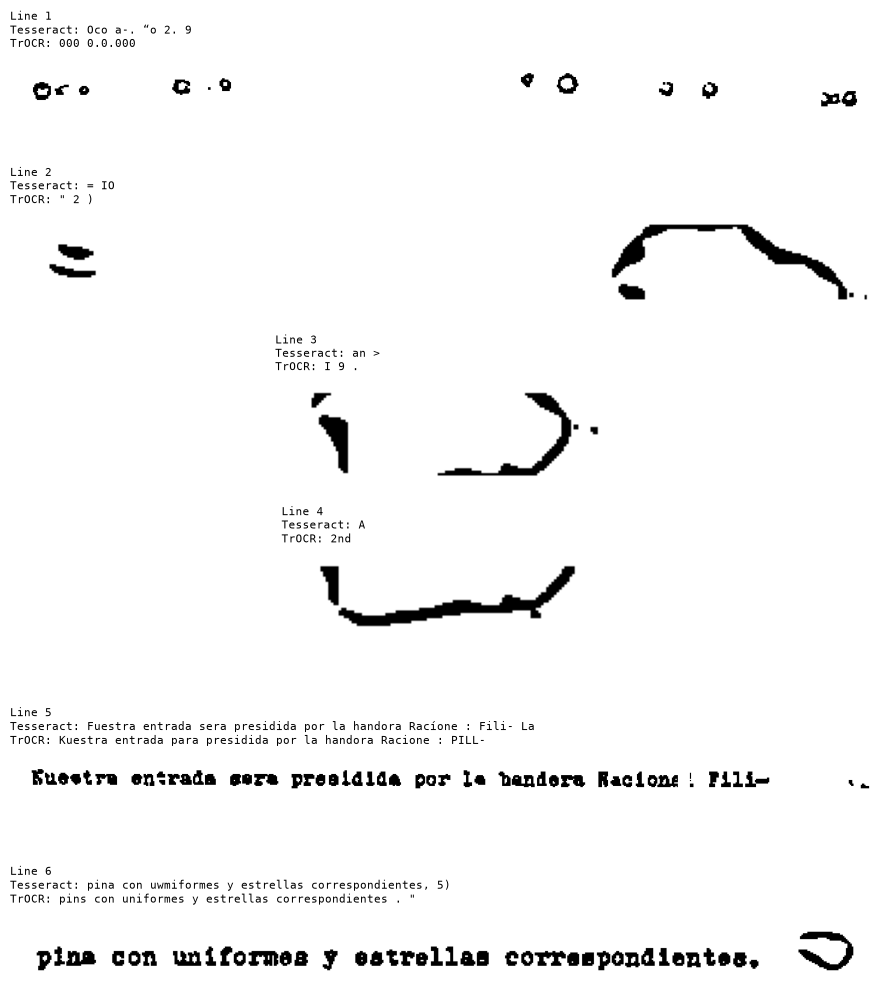

In [30]:
# Figure for the paper: each line image with its reading(s) under it (and the truth, when it lines up)
if boxes:
    n = min(6, len(boxes))
    fig, axes = plt.subplots(n, 1, figsize=(9, 1.7 * n))
    axes = np.atleast_1d(axes)
    for i, ax in enumerate(axes):
        ax.imshow(crops[DETAIL_VARIANT][i], cmap="gray", vmin=0, vmax=255)
        ax.axis("off")
        txt = f"Truth: {truth_lines[i]}" if counts_match else f"Line {i + 1}"
        for key in detail_keys:
            txt += f"\n{key[0].split()[0]}: {predictions[key][i]}"
        ax.set_title(txt, loc="left", fontsize=8, family="monospace")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "line_examples.png"), dpi=200)
    plt.show()

## Step 9. Spanish special characters
A rough check of how well each engine keeps accents and `ñ`. This **counts** the characters, it does not align them, so a character that was wrongly placed can still be counted. Use it as a hint, not as a metric.

In [31]:
SPECIAL = "áéíóúüñÁÉÍÓÚÜÑ¿¡"
def count_special(text):
    return sum(text.count(c) for c in SPECIAL)

if truth_lines:
    rows = [{"Source": "Ground truth", "Input image": "-", "Special characters": count_special(" ".join(truth_lines))}]
    for (mode, variant), pred in predictions.items():
        rows.append({"Source": mode, "Input image": variant, "Special characters": count_special(" ".join(pred))})
    pd.DataFrame(rows)
else:
    print("Skipped: this needs a ground truth (see Step 2 and Step 5b).")

## Step 10. Save everything

In [32]:
for (mode, variant), pred in predictions.items():
    fname = f"{mode.lower().replace(' ', '_')}__{variant}.txt"
    with open(os.path.join(OUT_DIR, fname), "w", encoding="utf-8") as f:
        f.write("\n".join(pred))
print("Saved to", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

Saved to ../outputs/recognition
['.ipynb_checkpoints', 'comparison.png', 'ground_truth_TEMPLATE.txt', 'line_examples.png', 'line_segmentation.png', 'lines', 'per_line_binarized.csv', 'results.csv', 'tesseract_full_page__binarized.txt', 'tesseract_full_page__grayscale.txt', 'tesseract_per_line__binarized.txt', 'tesseract_per_line__grayscale.txt', 'trocr_per_line__binarized.txt', 'trocr_per_line__grayscale.txt']


## What to report in the paper

1. **Method:** Tesseract (`spa`) as the OCR engine, TrOCR as the HTR engine, both on the same line crops from the same Stage 1 images; metrics are CER and WER (strict and relaxed).
2. **Table:** `results.csv` (engine, input image, CER, WER, time).
3. **Figures:** `comparison.png`, `line_segmentation.png`, `line_examples.png`.
4. **Discussion points:**
   - Which engine reads the manuscript better, and whether the binarized or grayscale input helped each one.
   - Tesseract is built for printed text and TrOCR's released model for English handwriting, so neither is trained for Philippine-American War Spanish. Errors on accents and period spellings are expected, and are the argument for fine-tuning on your own transcribed lines.
   - Speed: OCR is usually faster on CPU; TrOCR benefits from a GPU.
5. **Limits to state:** the size of your test set (one page gives only a rough estimate; use more pages), how the ground truth was made and who checked it, and that line segmentation errors affect both engines.